<a href="https://colab.research.google.com/github/pratapsingh23/uk-road-accident-severity-prediction/blob/main/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [123]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import folium
from folium.plugins import HeatMap

from data_loading import data_loading, files
df = data_loading(files['final_df'])

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513801 entries, 0 to 513800
Data columns (total 51 columns):
 #   Column                                             Non-Null Count   Dtype         
---  ------                                             --------------   -----         
 0   collision_index                                    513801 non-null  object        
 1   collision_severity                                 513801 non-null  int64         
 2   date                                               513801 non-null  datetime64[ns]
 3   day_of_week                                        513801 non-null  int64         
 4   time                                               513801 non-null  object        
 5   latitude                                           513748 non-null  float64       
 6   longitude                                          513748 non-null  float64       
 7   urban_or_rural_area                                513793 non-null  float64       
 8   spee

#**Exploratary Data Anyalysis**

In [3]:
df.columns

Index(['collision_index', 'collision_severity', 'date', 'day_of_week', 'time',
       'latitude', 'longitude', 'urban_or_rural_area', 'speed_limit',
       'road_type', 'light_conditions', 'weather_conditions',
       'road_surface_conditions', 'special_conditions_at_site',
       'carriageway_hazards', 'junction_detail', 'junction_control',
       'trunk_road_flag', 'number_of_vehicles', 'number_of_casualties',
       'did_police_officer_attend_scene_of_accident',
       'collision_severity_label', 'day_of_week_label',
       'urban_or_rural_area_label', 'road_type_label',
       'light_conditions_label', 'weather_conditions_label',
       'road_surface_conditions_label', 'special_conditions_at_site_label',
       'carriageway_hazards_label', 'junction_detail_label',
       'junction_control_label', 'trunk_road_flag_label',
       'did_police_officer_attend_scene_of_accident_label', 'min_driver_age',
       'max_driver_age', 'max_vehicle_age', 'max_engine_cc',
       'male_driver_shar

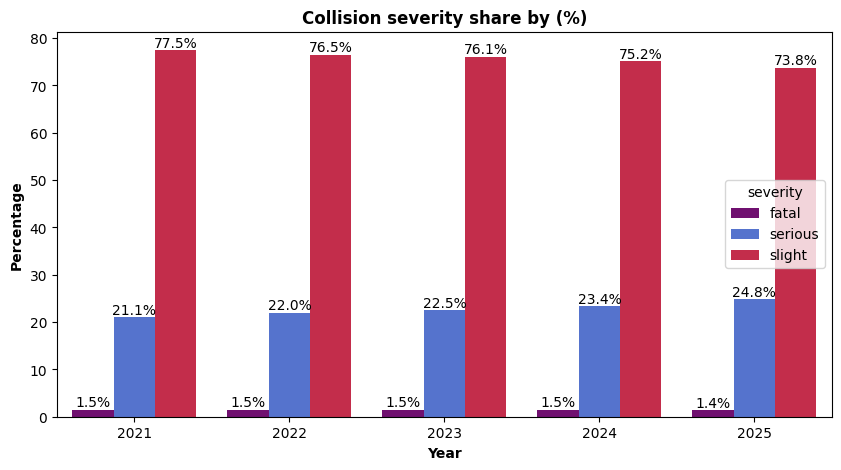

In [70]:

# Severity per years

pct = (
    df.groupby('year')['collision_severity_label']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename('percent')
    .reset_index()
)

# plot
fig, ax = plt.subplots(figsize=(10,5))
colors={
    'fatal': 'purple',
    'serious': 'royalblue',
    'slight': 'crimson'
}
sns.barplot(
    data=pct,
    x='year',
    y='percent',
    hue='collision_severity_label',
    hue_order=['fatal', 'serious', 'slight'],
    palette=colors,
    ax=ax
)


bars = [0, 1, 2]
for bar in bars:
  ax.bar_label(ax.containers[bar], fmt='%1.1f%%')

ax.set_title("Collision severity share by (%)", fontweight='bold')
ax.set_xlabel("Year", fontweight='semibold'),
ax.set_ylabel("Percentage", fontweight='semibold')
plt.legend(title='severity')
plt.show()

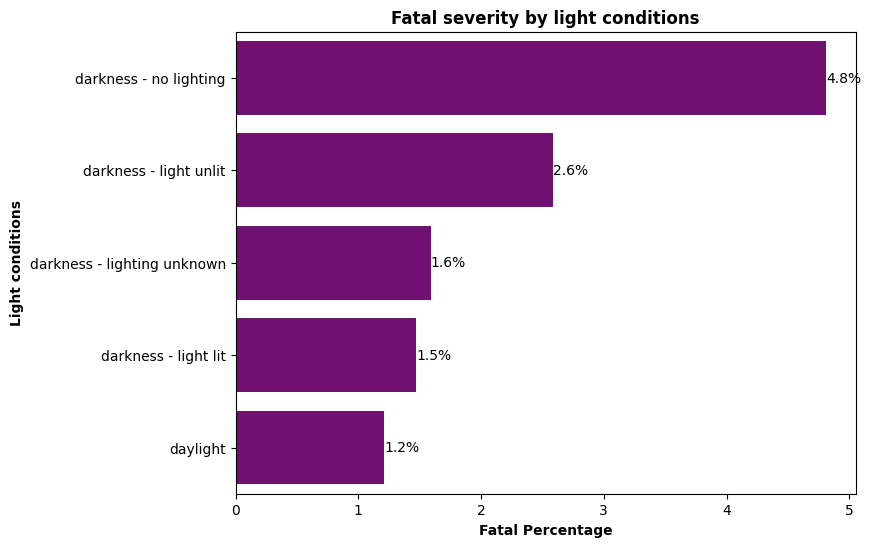

In [65]:
# Darkness vs Daylight:


df['fatal'] = df['collision_severity'].eq(1)

rate = (
    df.groupby('light_conditions_label', observed=True)['fatal']
    .agg(['mean', 'size'])
    .rename(columns={'mean': 'fatal_pct', 'size': 'total'})
)

rate['fatal_pct'] = (rate['fatal_pct'] * 100).round(2)
rate = rate.sort_values('fatal_pct', ascending=False).reset_index()

plot_rate = rate[rate['light_conditions_label'] != 'data missing or out of range']

fig, ax = plt.subplots(figsize=(8,6))
sns.barplot(
    data=plot_rate,
    x='fatal_pct',
    y='light_conditions_label',
    color='purple',
    ax=ax
)

ax.set_title("Fatal severity by light conditions", fontweight='bold')
ax.set_xlabel("Fatal Percentage", fontweight='semibold')
ax.set_ylabel("Light conditions", fontweight='semibold')
ax.bar_label(ax.containers[0], fmt='%1.1f%%')

plt.show()



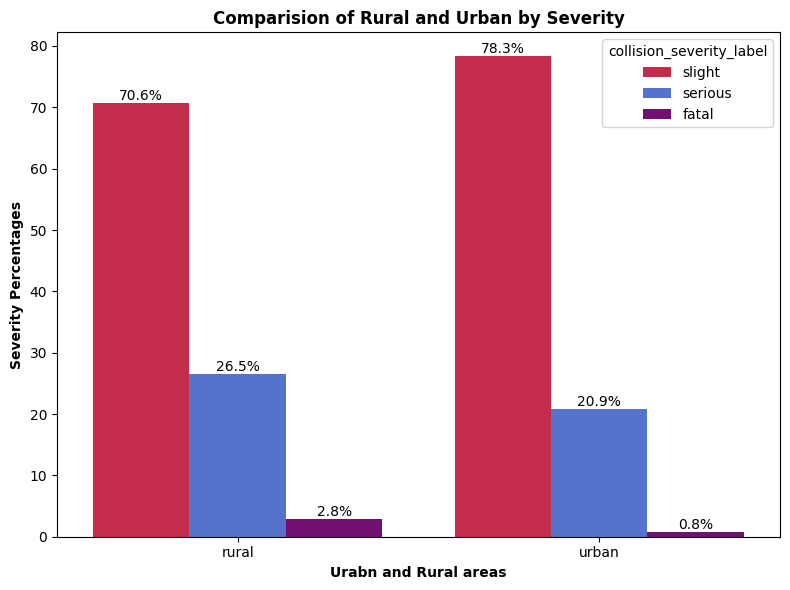

In [69]:
# Severity of Rural and Urban areas:

area_pct = (
    df.groupby('urban_or_rural_area_label')['collision_severity_label']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename('percent')
    .reset_index()
)

rural_sev_plot = area_pct[area_pct['urban_or_rural_area_label'].isin(['urban', 'rural'])]
fig, ax = plt.subplots(figsize=(8,6))
colors={
    'fatal': 'purple',
    'serious': 'royalblue',
    'slight': 'crimson'
}
sns.barplot(
    data=rural_sev_plot,
    x='urban_or_rural_area_label',
    y='percent',
    hue='collision_severity_label',
    palette=colors,
    ax=ax
)

ax.set_title("Comparision of Rural and Urban by Severity", fontweight='bold')
ax.set_xlabel("Urabn and Rural areas", fontweight='semibold')
ax.set_ylabel("Severity Percentages", fontweight='semibold')

bars = [0, 1, 2]
for bar in bars:
  ax.bar_label(ax.containers[bar], fmt='%1.1f%%')
plt.tight_layout()
plt.show()

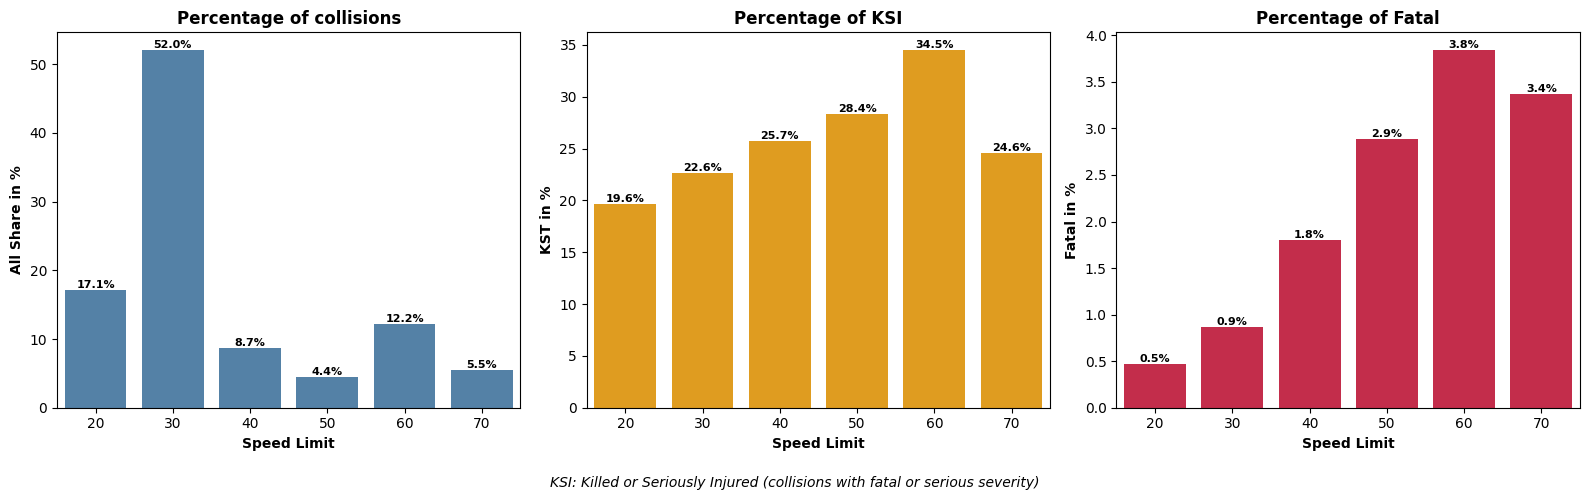

In [106]:
# df['speed_limit'].value_counts()

sp = df.dropna(subset=['speed_limit']).copy()
sp['speed_limit'] = sp['speed_limit'].astype('int')
sp['fatal'] = sp['collision_severity'].eq(1)
sp['ksi'] = sp['collision_severity'].isin([1, 2])

sp_data = (
    sp.groupby('speed_limit')
    .agg(
        total=('collision_index', 'size'),
        fatal_pct=('fatal', 'mean'),
        ksi_pct=('ksi', 'mean')
    )
    .reset_index()
)
sp_data['share_of_all_pct'] = ((sp_data['total']/sp_data['total'].sum()) * 100).round(2)
sp_data['fatal_pct'] = (sp_data['fatal_pct'] * 100).round(2)
sp_data['ksi_pct'] = (sp_data['ksi_pct'] * 100).round(2)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(
    data=sp_data,
    x='speed_limit',
    y='share_of_all_pct',
    color='steelblue',
    ax=axes[0]
)

sns.barplot(
    data=sp_data,
    x='speed_limit',
    y='ksi_pct',
    color='orange',
    ax=axes[1]
)

sns.barplot(
    data=sp_data,
    x='speed_limit',
    y='fatal_pct',
    color='crimson',
    ax=axes[2]
)

# bar label
points = [0, 1, 2]
for point in points:
  axes[point].bar_label(axes[point].containers[0], fmt="%1.1f%%",fontsize=8, fontweight='semibold')

# titles
axes[0].set_title("Percentage of collisions", fontweight='bold')
axes[1].set_title("Percentage of KSI", fontweight='bold')
axes[2].set_title("Percentage of Fatal", fontweight='bold')

# x labels
for point in points:
  axes[point].set_xlabel("Speed Limit", fontweight='semibold')

# y labels
axes[0].set_ylabel("All Share in %", fontweight='semibold')
axes[1].set_ylabel("KST in %", fontweight='semibold')
axes[2].set_ylabel("Fatal in %", fontweight='semibold')
fig.supxlabel("KSI: Killed or Seriously Injured (collisions with fatal or serious severity)",
              fontsize=10, style='italic')
plt.tight_layout()
plt.show()
plt.show()
plt.show()

In [126]:
severe_df = df[
    df['collision_severity'].isin([1, 2])
].copy()

geo_df = df.dropna(subset=['latitude', 'longitude']).copy()

geo_df['lat_grid'] = geo_df['latitude'].round(3)
geo_df['long_grid'] = geo_df['longitude'].round(3)

geo_df['is_fatal'] = geo_df['collision_severity'] == 1
geo_df['is_serious'] = geo_df['collision_severity'] == 2

location_analysis = (
    geo_df.groupby(['lat_grid', 'long_grid'])
    .agg(
        total_accidents=('collision_index', 'count'),
        fatal_accidents=('is_fatal', 'sum'),
        serious_accidents=('is_serious', 'sum')
    )
    .reset_index()
)

location_analysis['severe_accident_rate'] = (
    ((location_analysis['fatal_accidents'] + location_analysis['serious_accidents']) / location_analysis['total_accidents']) * 100

)

hotspot = location_analysis[
    location_analysis['total_accidents'] >= 30
].copy()

hotspot = hotspot.sort_values(
    'severe_accident_rate',
    ascending=False
)

m = folium.Map(
    location=[
        geo_df['latitude'].mean(),
        geo_df['longitude'].mean()
    ],
    zoom_start=6,
    tiles=None
)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Esri',
    name='Esri World Street Map'
).add_to(m)

HeatMap(
    hotspot[['lat_grid', 'long_grid']].values.tolist()
).add_to(m)

m


In [121]:
print(hotspot)

        lat_grid  long_grid  total_accidents  fatal_accidents  \
17896     50.830     -0.755               31                0   
36603     51.122     -0.199               31                0   
58199     51.365     -0.118               31                0   
62199     51.387     -0.111               30                0   
62379     51.388     -0.111               32                0   
...          ...        ...              ...              ...   
116947    51.613     -0.065               49                0   
122916    51.660     -0.059               30                0   
130608    51.750     -1.244               48                1   
138973    51.868      0.582               30                0   
173412    52.473     -1.875               38                0   

        serious_accidents  severe_accident_rate  
17896                   4             12.903226  
36603                   2              6.451613  
58199                   4             12.903226  
62199              